# Session 5c — The bootstrap and the wild bootstrap

Econometrics (PhD), CGDE / IWH Halle — Felix Noth

Companion to the bootstrap block of lecture AE1.3 (Fixed Effects and
Standard Errors). Everything is simulated, so the true sampling variability
is known and every standard error can be judged against it.

1. The idea: bootstrap the standard error of a sample mean and compare it to
   the formula.
2. OLS with heteroskedasticity, $n = 30$ banks: residual, pairs and wild
   bootstrap standard errors against the true sampling SD.
3. Rejection rates of a 5% test: conventional, HC1, HC3, pairs bootstrap, and
   the wild bootstrap-$t$ (restricted residuals, Rademacher weights).
4. A quantity with no easy formula: a ratio of coefficients, delta method vs.
   bootstrap percentile interval.

Readings: Efron (1979); Liu (1988); Mammen (1993); Davidson and Flachaire
(2008); MacKinnon (2006). The wild *cluster* bootstrap (Cameron, Gelbach and
Miller 2008) is Set AE2. Full references at the end.

Requirements: `numpy`, `pandas`, `statsmodels`, `matplotlib`.

In [1]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
from scipy import stats
import warnings; warnings.filterwarnings("ignore")

rng = np.random.default_rng(20261116)
pd.set_option("display.precision", 4)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")

BLUE, ORANGE, VERMILLION, GREEN, GREY = "#0072B2", "#E69F00", "#D55E00", "#009E73", "#999999"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e6e6", "grid.linewidth": 0.6, "font.family": "sans-serif"})

## 1. The idea, on the sample mean

We have one sample and want to know how much $\bar y$ would move across
repeated samples. The bootstrap answers by *treating the sample as the
population*: draw $n$ observations from it with replacement, compute the
mean, repeat $B$ times. The SD of the $B$ bootstrap means is the bootstrap
standard error (Efron 1979).

Loan growth of 200 banks, drawn from a skewed distribution (a few banks grow
a lot). The formula $s/\sqrt{n}$ exists here, so we can check the bootstrap
against it — and both against the truth from 10,000 fresh samples.

In [2]:
n, B = 200, 999
pop = lambda size: rng.gamma(2, 2, size)                         # skewed "loan growth"
y = pop(n)

boot_means = np.array([rng.choice(y, n, replace=True).mean() for _ in range(B)])
true_sd = np.array([pop(n).mean() for _ in range(10_000)]).std()

print(f"sample mean {y.mean():.3f}")
print(f"formula SE      s/sqrt(n) = {y.std(ddof=1) / np.sqrt(n):.3f}")
print(f"bootstrap SE    SD of {B} bootstrap means = {boot_means.std(ddof=1):.3f}")
print(f"true SD of the sample mean (10,000 fresh samples) = {true_sd:.3f}")

sample mean 4.000
formula SE      s/sqrt(n) = 0.195
bootstrap SE    SD of 999 bootstrap means = 0.198
true SD of the sample mean (10,000 fresh samples) = 0.201


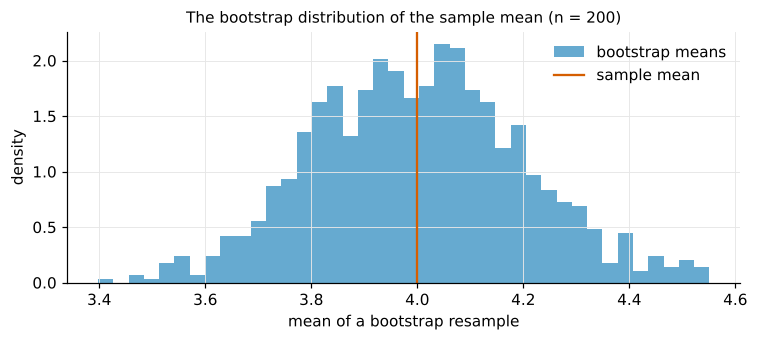

In [3]:
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(boot_means, bins=40, color=BLUE, alpha=0.6, density=True, label="bootstrap means")
ax.axvline(y.mean(), color=VERMILLION, lw=1.5, label="sample mean")
ax.set_xlabel("mean of a bootstrap resample"); ax.set_ylabel("density"); ax.legend(frameon=False)
ax.set_title("The bootstrap distribution of the sample mean (n = 200)", fontsize=10)
plt.tight_layout(); plt.show()

Nothing in the bootstrap knew the formula. It got the same number because
resampling from the sample mimics sampling from the population — which is
all the formula does analytically. The payoff comes where there is no
formula, or where the formula is only right asymptotically.

## 2. Three bootstraps for a regression, $n = 30$ banks

Cross-section of 30 banks: loan growth $y_i$ on the capital ratio $x_i$,
true slope $\beta = 1$. The capital ratio is skewed (a few very
well-capitalised banks) and the error variance *rises with it* — exactly the
situation in which heteroskedasticity-robust SEs are needed and, with
$n = 30$, not yet reliable.

$$ y_i = 1 + \beta x_i + \varepsilon_i, \qquad \varepsilon_i \sim N\big(0,\ (0.3 + 0.5\,x_i)^2\big). $$

Three ways to resample:

- **Residual bootstrap.** Keep $X$ fixed; draw residuals $\hat\varepsilon_i$
  with replacement and attach them to *any* observation:
  $y_i^* = x_i'\hat\beta + \hat\varepsilon_{j(i)}$. This mixes residuals across
  observations, so it imposes homoskedasticity.
- **Pairs bootstrap.** Resample rows $(y_i, x_i)$. Each row keeps its own
  variance, so heteroskedasticity is respected — but the design changes in
  every draw (some draws have no very-well-capitalised bank at all).
- **Wild bootstrap.** Keep $X$ fixed *and* keep each residual at its own
  observation, only flip its sign at random:
  $y_i^* = x_i'\hat\beta + \hat\varepsilon_i\, v_i$, $v_i \in \{-1, +1\}$ with
  probability ½ each (Rademacher). $E[\hat\varepsilon_i v_i] = 0$ and
  $\operatorname{Var}(\hat\varepsilon_i v_i) = \hat\varepsilon_i^2$: every
  observation keeps its own variance (Liu 1988; Mammen 1993).

In [4]:
def make_banks(n=30, beta=1.0, rng=rng):
    x = rng.gamma(2, 1.5, n)                                     # skewed capital ratio (in %)
    eps = rng.normal(0, 0.3 + 0.5 * x)                           # variance rises with x
    y = 1 + beta * x + eps
    return x, y

def ols(X, y):
    XtX_inv = np.linalg.inv(X.T @ X)
    b = XtX_inv @ X.T @ y
    e = y - X @ b
    return b, e, XtX_inv

def hc_se(X, e, XtX_inv, kind="HC1"):
    n, K = X.shape
    if kind == "HC1":
        w = e**2 * n / (n - K)
    elif kind == "HC3":
        h = np.einsum("ij,jk,ik->i", X, XtX_inv, X)
        w = e**2 / (1 - h)**2
    else:                                                         # conventional
        w = np.full(n, e @ e / (n - K))
    V = XtX_inv @ (X.T * w) @ X @ XtX_inv
    return np.sqrt(np.diag(V))

def boot_se(X, y, B=999, kind="wild", rng=rng):
    # Returns the bootstrap SE of the slope (column 1) for the three schemes.
    n = len(y); b, e, XtX_inv = ols(X, y); A = XtX_inv @ X.T       # b* = b + A @ (perturbed residual)
    if kind == "residual":
        E = e[rng.integers(0, n, (B, n))]                          # residuals reshuffled across observations
        bs = b[1] + E @ A[1]
    elif kind == "wild":
        V = rng.choice([-1.0, 1.0], (B, n))                        # Rademacher
        bs = b[1] + (e * V) @ A[1]
    elif kind == "pairs":
        idx = rng.integers(0, n, (B, n))
        Xb, yb = X[idx], y[idx]                                    # B x n x K, B x n
        XtX = np.einsum("bik,bil->bkl", Xb, Xb); Xty = np.einsum("bik,bi->bk", Xb, yb)
        bs = np.linalg.solve(XtX, Xty[..., None])[:, 1, 0]
    return bs.std(ddof=1)

def all_ses(rng):
    x, y = make_banks(rng=rng); X = np.column_stack([np.ones(len(x)), x]); b, e, XtX_inv = ols(X, y)
    return {"conventional (homoskedastic)": hc_se(X, e, XtX_inv, "conv")[1],
            "HC1 (Stata robust)":           hc_se(X, e, XtX_inv, "HC1")[1],
            "HC3":                          hc_se(X, e, XtX_inv, "HC3")[1],
            "residual bootstrap":           boot_se(X, y, B=399, kind="residual", rng=rng),
            "pairs bootstrap":              boot_se(X, y, B=399, kind="pairs", rng=rng),
            "wild bootstrap (Rademacher)":  boot_se(X, y, B=399, kind="wild", rng=rng),
            "slope estimate":               b[1]}

R = 1000
draws = pd.DataFrame([all_ses(rng) for _ in range(R)])
out = draws.drop(columns="slope estimate").mean().rename("average SE across samples")
out["true sampling SD of the slope"] = draws["slope estimate"].std(ddof=1)
out.to_frame()

,average SE across samples
conventional (homoskedastic),0.1782
HC1 (Stata robust),0.2304
HC3,0.2929
residual bootstrap,0.1720
pairs bootstrap,0.2481
wild bootstrap (Rademacher),0.2225
true sampling SD of the slope,0.3019


Averaged over 1,000 samples (one sample alone wobbles too much at $n=30$ to
read). The pattern: the conventional SE and the residual bootstrap sit
together and well below the truth — both assume one variance for all banks.
HC1, pairs and wild sit together, higher but still short: at $n = 30$ the
squared residuals underestimate the error variance where the fit is good,
and the wild bootstrap SE inherits that, because conditional on the sample
it is HC0 computed by simulation (HC1 is HC0 scaled by $n/(n-K)$). HC3
compensates and comes closest. Two lessons:
resampling is not automatically robust (the scheme has to respect the
heteroskedasticity), and a bootstrap *standard error* is not automatically
better than an analytic one.

## 3. Does the test have the right size? Rejection rates at $n = 30$

A standard error is only as good as the test built on it. Repeat the
experiment 2,000 times under the truth $\beta = 1$ and count how often a
nominal 5% test of $H_0\!: \beta = 1$ rejects. A correct test rejects 5% of the
time.

Two ways to use a bootstrap for the test:

- **Bootstrap SE** in the usual $t = (\hat\beta - 1)/\widehat{SE}_{boot}$,
  compared to $\pm 1.96$.
- **Bootstrap-$t$** (Davidson and Flachaire 2008): generate the bootstrap
  samples with $H_0$ imposed (restricted residuals: fitted values and
  residuals from the regression with $\beta = 1$ imposed), compute the
  $t$-statistic *in each bootstrap sample*,
  $t^*_b = (\hat\beta^*_b - \beta_0)/\widehat{SE}^*_b$ with HC1 inside —
  centred on $\beta_0$, which is the truth in the bootstrap world — and
  compare the sample $t$ to the distribution of the $t^*_b$ instead of to the
  normal. The $p$-value is $(1 + \#\{|t^*_b| \ge |t|\})/(B+1)$.

In [5]:
def wild_boot_t(X, y, beta0, B=399, rng=rng):
    # Wild bootstrap-t for H0: slope = beta0, restricted residuals, Rademacher weights, HC1 inside. Returns the p-value.
    n, K = X.shape
    b, e, XtX_inv = ols(X, y)
    t_hat = (b[1] - beta0) / hc_se(X, e, XtX_inv, "HC1")[1]
    y_r = y - X[:, 1] * beta0                                      # impose H0, fit the rest
    Xr = X[:, [0]]; br = np.linalg.lstsq(Xr, y_r, rcond=None)[0]
    e_r = y_r - Xr @ br
    fitted_r = X[:, 1] * beta0 + Xr @ br
    V = rng.choice([-1.0, 1.0], (B, n))
    Ys = fitted_r + e_r * V                                        # B x n bootstrap outcomes
    A = XtX_inv @ X.T
    Bs = Ys @ A.T                                                  # B x K bootstrap coefficients
    Es = Ys - Bs @ X.T                                             # B x n bootstrap residuals
    se_s = np.sqrt((Es**2 * n / (n - K)) @ (A[1]**2))              # HC1 SE of the slope, every bootstrap sample
    t_s = (Bs[:, 1] - beta0) / se_s
    return (1 + (np.abs(t_s) >= abs(t_hat)).sum()) / (B + 1)              # finite-B p-value

def one_rep(rng):
    x, y = make_banks(rng=rng); X = np.column_stack([np.ones(len(x)), x])
    b, e, XtX_inv = ols(X, y); dev = b[1] - 1.0
    rej = {k: abs(dev / hc_se(X, e, XtX_inv, k)[1]) > 1.96 for k in ["conv", "HC1", "HC3"]}
    rej["pairs bootstrap SE"] = abs(dev / boot_se(X, y, B=199, kind="pairs", rng=rng)) > 1.96
    rej["wild bootstrap SE"]  = abs(dev / boot_se(X, y, B=199, kind="wild", rng=rng)) > 1.96
    rej["wild bootstrap-t"]   = wild_boot_t(X, y, 1.0, B=199, rng=rng) < 0.05
    return rej

R = 2000
rejections = pd.DataFrame([one_rep(rng) for _ in range(R)]).mean().rename({"conv": "conventional", "HC1": "HC1", "HC3": "HC3"})
rejections.to_frame("rejection rate of a nominal 5% test").T

,conventional,HC1,HC3,pairs bootstrap SE,wild bootstrap SE,wild bootstrap-t
rejection rate of a nominal 5% test,0.2665,0.1770,0.1135,0.1365,0.1895,0.0665


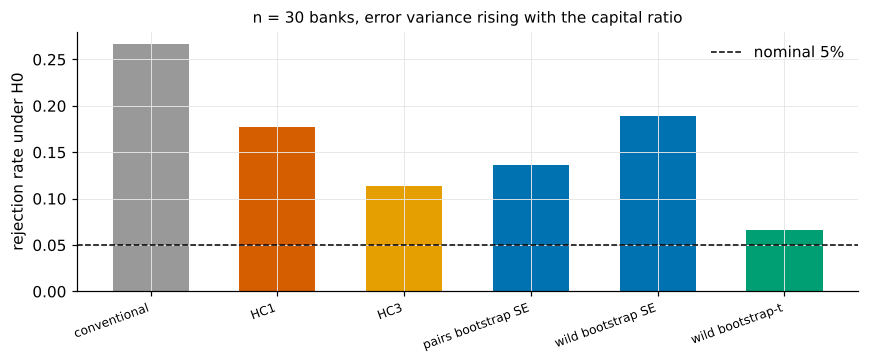

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.bar(rejections.index, rejections.values, color=[GREY, VERMILLION, ORANGE, BLUE, BLUE, GREEN], width=0.6)
ax.axhline(0.05, color="black", ls="--", lw=1, label="nominal 5%")
ax.set_ylabel("rejection rate under H0"); ax.set_xticklabels(rejections.index, rotation=20, ha="right", fontsize=8)
ax.legend(frameon=False); ax.set_title("n = 30 banks, error variance rising with the capital ratio", fontsize=10)
plt.tight_layout(); plt.show()

The conventional test is the worst — not because of its formula alone but
because the heteroskedasticity is tied to a skewed regressor. HC1, the Stata
`robust` default, still over-rejects by a factor of three at $n = 30$, and a
wild bootstrap *standard error* plugged into the usual $t$-test does no
better — it is HC0, simulated. HC3 helps. The **wild
bootstrap-$t$** is the one closest to 5%: it does not produce a better SE, it
replaces the normal reference distribution by the one the data actually
generate, including the small-sample behaviour of the SE in the denominator.
That is why "bootstrap the SE" and "bootstrap the test" are different
recommendations, and the second is the one the literature makes (MacKinnon
2006; Davidson and Flachaire 2008).

### Why the bootstrap-$t$ works: the reference distribution

The HC1 $t$-statistic at $n = 30$ is not standard normal. Its denominator is
noisy and biased downward: squared residuals underestimate the error variance
where the fit is tight, and with a skewed capital ratio the well-capitalised
banks have high leverage, so the fit is tightest exactly where the variance
is largest. The bootstrap-$t$ draws $t^*$ under $H_0$ with the same 30 banks,
the same skewed $x$ and the same HC1 denominator, so $t^*$ has the same fat
tails. Its 97.5% quantile — not 1.96 — is the critical value. Below: the
distribution of $|t^*|$ in one sample, and the average bootstrap critical
value across 500 samples.

bootstrap critical value (95% quantile of |t*|), this sample: 2.05;  average over 500 samples: 2.89;  normal: 1.96


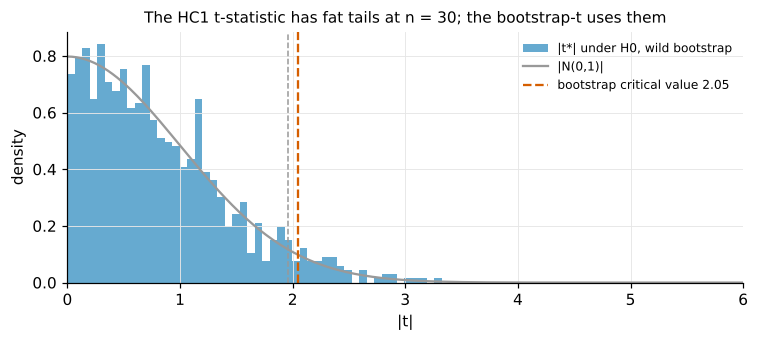

In [7]:
def wild_boot_tstar(X, y, beta0, B=999, rng=rng):
    n, K = X.shape; b, e, XtX_inv = ols(X, y)
    y_r = y - X[:, 1] * beta0; Xr = X[:, [0]]; br = np.linalg.lstsq(Xr, y_r, rcond=None)[0]
    e_r = y_r - Xr @ br; fitted_r = X[:, 1] * beta0 + Xr @ br
    V = rng.choice([-1.0, 1.0], (B, n)); Ys = fitted_r + e_r * V
    A = XtX_inv @ X.T; Bs = Ys @ A.T; Es = Ys - Bs @ X.T
    se_s = np.sqrt((Es**2 * n / (n - K)) @ (A[1]**2))
    return (Bs[:, 1] - beta0) / se_s

x, y = make_banks(); X = np.column_stack([np.ones(len(x)), x])
t_star = wild_boot_tstar(X, y, 1.0)
crit_one = np.percentile(np.abs(t_star), 95)
crit_avg = np.mean([np.percentile(np.abs(wild_boot_tstar(*(lambda x, y: (np.column_stack([np.ones(len(x)), x]), y))(*make_banks()), 1.0, B=399)), 95) for _ in range(500)])
print(f"bootstrap critical value (95% quantile of |t*|), this sample: {crit_one:.2f};  average over 500 samples: {crit_avg:.2f};  normal: 1.96")

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(np.abs(t_star), bins=50, density=True, color=BLUE, alpha=0.6, label="|t*| under H0, wild bootstrap")
xs = np.linspace(0, 6, 300); ax.plot(xs, 2 * stats.norm.pdf(xs), color=GREY, lw=1.5, label="|N(0,1)|")
ax.axvline(1.96, color=GREY, ls="--", lw=1); ax.axvline(crit_one, color=VERMILLION, ls="--", lw=1.5, label=f"bootstrap critical value {crit_one:.2f}")
ax.set_xlim(0, 6); ax.set_xlabel("|t|"); ax.set_ylabel("density"); ax.legend(frameon=False, fontsize=8)
ax.set_title("The HC1 t-statistic has fat tails at n = 30; the bootstrap-t uses them", fontsize=10)
plt.tight_layout(); plt.show()

## 4. A quantity without a convenient formula: a ratio of coefficients

Lending growth on the capital ratio $x_1$ and the liquidity ratio $x_2$,
and the question is their *relative* weight, $\theta = \beta_1/\beta_2$ — how
much liquidity substitutes for a point of capital. The delta method gives
$\widehat{SE}(\hat\theta)$ from a first-order expansion; it is fine when
$\hat\beta_2$ is far from zero and poor when it is not, because the ratio's
distribution is then skewed and the symmetric interval is wrong on one side.

The pairs bootstrap needs no formula: compute $\hat\theta^*$ in each
resample and read off the 2.5% and 97.5% quantiles (percentile interval).
Compare coverage of the true $\theta$ over 2,000 samples.

In [8]:
def make_banks2(n=30, b1=1.0, b2=0.4, rng=rng):
    x1 = rng.gamma(2, 1.5, n); x2 = rng.normal(0, 1, n)
    y = 1 + b1 * x1 + b2 * x2 + rng.normal(0, 0.3 + 0.5 * x1)
    return np.column_stack([np.ones(n), x1, x2]), y

theta_true = 1.0 / 0.4

def cover_once(rng, B=399):
    X, y = make_banks2(rng=rng); n = len(y)
    b, e, XtX_inv = ols(X, y); theta = b[1] / b[2]
    # delta method with HC1 covariance
    w = e**2 * n / (n - X.shape[1]); V = XtX_inv @ (X.T * w) @ X @ XtX_inv
    g = np.array([0, 1 / b[2], -b[1] / b[2]**2]); se_d = np.sqrt(g @ V @ g)
    delta_ok = abs(theta - theta_true) <= 1.96 * se_d
    # pairs bootstrap percentile interval
    idx = rng.integers(0, n, (B, n)); Xb, yb = X[idx], y[idx]
    XtX = np.einsum("bik,bil->bkl", Xb, Xb); Xty = np.einsum("bik,bi->bk", Xb, yb)
    bs = np.linalg.solve(XtX, Xty[..., None])[..., 0]; th = bs[:, 1] / bs[:, 2]
    lo, hi = np.percentile(th, [2.5, 97.5])
    return {"delta method (HC1), ±1.96 SE": delta_ok, "pairs bootstrap, percentile interval": lo <= theta_true <= hi}

coverage = pd.DataFrame([cover_once(rng) for _ in range(2000)]).mean()
coverage.to_frame("coverage of a nominal 95% interval for β1/β2").T

,"delta method (HC1), ±1.96 SE","pairs bootstrap, percentile interval"
coverage of a nominal 95% interval for β1/β2,0.8035,0.9565


With $\beta_2 = 0.4$ and $n = 30$, $\hat\beta_2$ is often close to zero and the
ratio's sampling distribution has a long tail; the delta-method interval,
symmetric by construction, undercovers. The percentile interval follows the
skew because it is read off the bootstrap distribution itself. This is one
DGP, not a theorem: when the denominator can cross zero the ratio has no
finite moments and percentile intervals become unstable too; the exact
answer for a ratio is Fieller's method (inverting the test of
$\beta_1 - \theta\beta_2 = 0$). Same lesson as Section 3 from the other
side: the bootstrap earns its keep where the analytic approximation is the
weak link.

## Summary

- The bootstrap estimates sampling variability by resampling the sample;
  where a formula exists it reproduces it, where none exists it still works.
- Resampling is not automatically robust: the residual bootstrap imposes
  homoskedasticity. Pairs and wild bootstraps respect it; the wild bootstrap
  does so with the design held fixed, which is what you want with skewed
  regressors or dummies.
- For tests, bootstrap the *statistic*, not just the SE: the wild
  bootstrap-$t$ with restricted residuals has close to correct size at
  $n = 30$, where HC1 over-rejects.
- For functions of coefficients, a percentile interval can follow the skew
  that the delta method cannot — here it does; Fieller's method is the
  exact answer for a ratio.
- Few clusters: the same idea at the cluster level — the wild cluster
  bootstrap (Cameron, Gelbach and Miller 2008) — in Set AE2.

## References

- Cameron, A. C., J. B. Gelbach, and D. L. Miller (2008). Bootstrap-based
  improvements for inference with clustered errors. *Review of Economics and
  Statistics* 90(3), 414–427.
- Davidson, R., and E. Flachaire (2008). The wild bootstrap, tamed at last.
  *Journal of Econometrics* 146(1), 162–169.
- Efron, B. (1979). Bootstrap methods: Another look at the jackknife. *Annals
  of Statistics* 7(1), 1–26.
- Liu, R. Y. (1988). Bootstrap procedures under some non-i.i.d. models.
  *Annals of Statistics* 16(4), 1696–1708.
- MacKinnon, J. G. (2006). Bootstrap methods in econometrics. *Economic
  Record* 82(s1), S2–S18.
- Mammen, E. (1993). Bootstrap and wild bootstrap for high dimensional linear
  models. *Annals of Statistics* 21(1), 255–285.